# 5.2 Число π и статистическая ошибка

# 5.2 圆周率与统计误差

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})

Matplotlib is building the font cache; this may take a moment.


## Попадания в четверть круга
Равномерные точки заполняют единичный квадрат. Доля попаданий в четверть круга оценивает $p=\pi/4$.

## 落入四分之一圆的点
在单位正方形中均匀采样。落入四分之一圆的比例估计 $p=\pi/4$。

In [2]:
rng = np.random.default_rng(42)
N = 100_000
x = rng.random(N)
y = rng.random(N)
inside = x**2 + y**2 <= 1
pi_mc = 4 * inside.mean()
print(f"pi_mc = {pi_mc:.5f}")
print(f"pi    = {np.pi:.5f}")

pi_mc = 3.13776
pi    = 3.14159


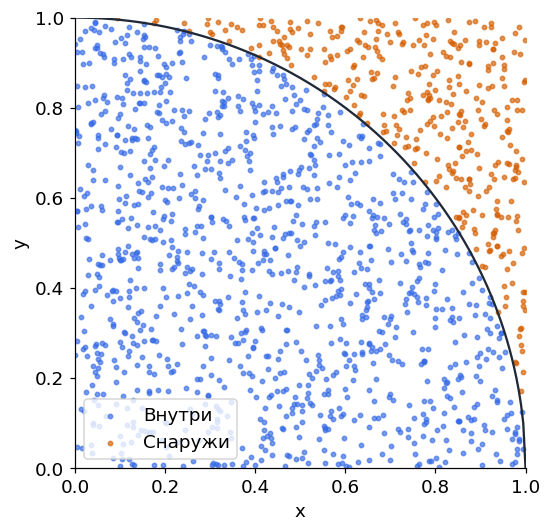

In [3]:
shown = 1500
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(x[:shown][inside[:shown]], y[:shown][inside[:shown]],
           s=8, alpha=0.65, label="Внутри")
ax.scatter(x[:shown][~inside[:shown]], y[:shown][~inside[:shown]],
           s=8, alpha=0.65, color="#D55E00", label="Снаружи")
q = np.linspace(0, 1, 200)
ax.plot(q, np.sqrt(1 - q**2), color="#202938")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x", ylabel="y", aspect="equal")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

## Стандартная ошибка
Для независимых попаданий $SE\approx4\sqrt{\hat p(1-\hat p)/N}$. Интервал $\pi_{MC}\pm1.96SE$ имеет приближённое покрытие 95% при большом $N$. Он не гарантирует попадание истинного значения в каждом опыте.

## 标准误
独立采样时，$SE\approx4\sqrt{\hat p(1-\hat p)/N}$。大样本下，区间 $\pi_{MC}\pm1.96SE$ 的覆盖率近似为 95%，并不保证每次试验都包含真值。

In [4]:
p_hat = inside.mean()
se_pi = 4 * np.sqrt(p_hat * (1 - p_hat) / N)
ci_pi = (pi_mc - 1.96 * se_pi, pi_mc + 1.96 * se_pi)
print(f"SE = {se_pi:.6f}")
print(f"95% CI: [{ci_pi[0]:.6f}, {ci_pi[1]:.6f}]")

SE = 0.005201
95% CI: [3.127565, 3.147955]


## Одна последовательность оценок
Берём первые $n$ пар из уже созданной выборки. Ошибка отдельной реализации может как уменьшаться, так и увеличиваться.

## 一条估计序列
每次使用已有样本的前 $n$ 对坐标。单次实现的误差既可能减小，也可能增大。

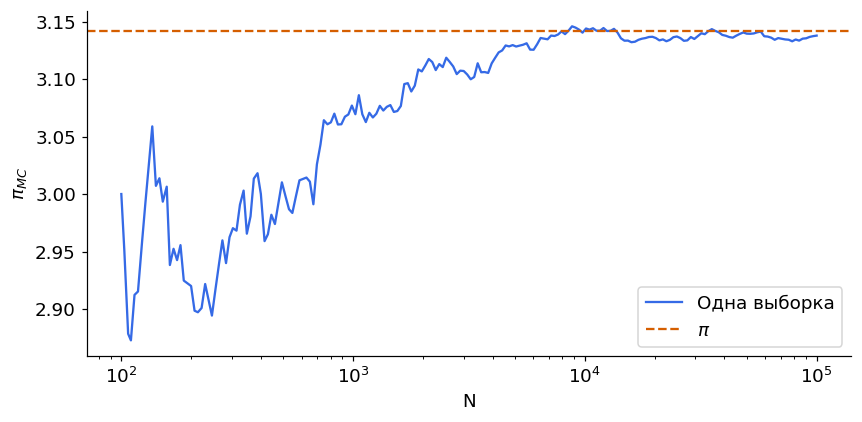

In [5]:
sizes = np.unique(np.geomspace(100, N, 200).astype(int))
pi_path = 4 * np.cumsum(inside)[sizes - 1] / sizes
fig, ax = plt.subplots()
ax.semilogx(sizes, pi_path, label="Одна выборка")
ax.axhline(np.pi, color="#D55E00", linestyle="--", label=r"$\pi$")
ax.set(xlabel="N", ylabel=r"$\pi_{MC}$")
ax.legend()
fig.tight_layout()
plt.show()

## Независимые повторы
Для каждого $N$ выполним 30 опытов. Генератор создаём один раз перед циклами. RMSE сравниваем с теоретическим $4\sqrt{p(1-p)/N}$, где $p=\pi/4$.

## 独立重复试验
每个 $N$ 重复 30 次。生成器只在循环前创建一次。将 RMSE 与理论值 $4\sqrt{p(1-p)/N}$ 比较，其中 $p=\pi/4$。

In [6]:
def estimate_pi(n, rng):
    x = rng.random(n)
    y = rng.random(n)
    return 4 * np.mean(x**2 + y**2 <= 1)

rng_repeats = np.random.default_rng(2026)
sample_sizes = np.array([100, 1000, 10_000, 100_000, 1_000_000])
R = 30
estimates = np.empty((sample_sizes.size, R))
for j, n in enumerate(sample_sizes):
    for r in range(R):
        estimates[j, r] = estimate_pi(n, rng_repeats)
rmse = np.sqrt(np.mean((estimates - np.pi)**2, axis=1))
p = np.pi / 4
rmse_theory = 4 * np.sqrt(p * (1 - p) / sample_sizes)
for n, error, theory in zip(sample_sizes, rmse, rmse_theory):
    print(f"N={n:7d}: RMSE={error:.6f}, theory={theory:.6f}")

N=    100: RMSE=0.221772, theory=0.164218
N=   1000: RMSE=0.046572, theory=0.051930
N=  10000: RMSE=0.016165, theory=0.016422
N= 100000: RMSE=0.005481, theory=0.005193
N=1000000: RMSE=0.001672, theory=0.001642


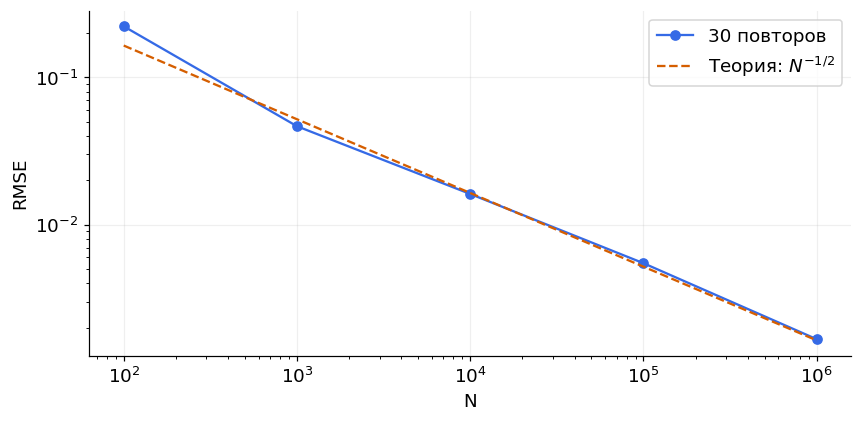

In [7]:
fig, ax = plt.subplots()
ax.loglog(sample_sizes, rmse, "o-", label="30 повторов")
ax.loglog(sample_sizes, rmse_theory, "--", color="#D55E00", label=r"Теория: $N^{-1/2}$")
ax.set(xlabel="N", ylabel="RMSE")
ax.grid(True, which="major", alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

## Попробуйте
Увеличьте число повторов до 100. Насколько изменился график RMSE? Чтобы уменьшить типичную ошибку в 10 раз, требуется примерно в 100 раз больше точек.

## 练习
把重复次数增加至 100，观察 RMSE 曲线的变化。要把典型误差缩小至原来的 1/10，通常需要约 100 倍的采样点。